# LSTM assignment · test an idea fairly

Predict next month's airline passenger total from recent monthly observations. The historical dataset has a trend and a recurring annual pattern, giving us a concrete reason to compare against the same month last year.

**Outcome:** explain the input shape, keep future information out of fitting, train a compact
recurrent model, and compare it with a simple baseline on identical target dates.

**Suggested time:** 20–30 minutes after the walkthrough.
This is a runnable starter. The working pipeline is supplied; your work is the experiment, evidence and explanation in the learner response cells. The final test is gated until you finish validation.


In [27]:
import os
from pathlib import Path

# This must happen before importing keras. Restart the kernel to change backend.
os.environ.setdefault("KERAS_BACKEND", "torch")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True})
print("Configured Keras backend:", os.environ["KERAS_BACKEND"])


Configured Keras backend: torch


## Your core tasks

1. **Audit the data.** Explain which row is excluded and why. Write the correct `(samples,
   timesteps, features)` meaning, and explain why fitting a scaler on all 144 months would leak
   future information. Predict whether later scaled values can exceed 1.
2. **Form a hypothesis.** Compare **6, 12 and 24 months** of history. Before training, state which
   you expect to help with annual seasonality and why. Change only `LOOKBACK`; keep dates,
   units, seed, optimizer and stopping rule fixed. Re-run sections 1–6 for each configuration.
3. **Record evidence.** Fill the table with validation MAE/RMSE and epochs run for all three
   windows. Include both persistence and seasonal-naive baseline scores. Explain whether a
   longer input improved validation and whether the training sample count changed.
4. **Choose and freeze.** Select the neural configuration by validation MAE, record it, then
   re-run sections 1–6 using that configuration. Set `RUN_FINAL_TEST = True` once.
   Report all final test scores and explain one reason the result may not generalize.

**Success criteria:** three controlled runs; correct 3D inputs; train-only scaler;
equal validation/test target dates across runs; baselines in thousands of passengers;
a documented selection followed by one final test. A baseline may be the best method.

**Hint:** the seasonal baseline always uses `t - 12`, even when the network uses a six-month
input. A baseline and a neural network may have different inputs while sharing the same
information-availability rule and target dates.


## 1 · Load the original dated observations and choose a small configuration


In [28]:
# Change one setting at a time during the core experiment.
LOOKBACK = 12
UNITS = 16
MAX_EPOCHS = 30
BATCH_SIZE = 8
LEARNING_RATE = 0.001


In [29]:
# Leave as None when using the complete pack. Otherwise point to your CSV folder.
DATA_DIR = None  # Example: Path("/path/to/bootcamp/data")

def data_file(filename, dataset_handle):
    """Prefer the supplied CSV; use the exact public dataset version if needed."""
    roots = ([Path(DATA_DIR).expanduser()] if DATA_DIR is not None else
             [Path("data"), Path("../data"), Path("../../data"), Path(".")])
    for folder in roots:
        candidate = folder / filename
        if candidate.is_file():
            return candidate.resolve()
    try:
        import kagglehub
        folder = Path(kagglehub.dataset_download(dataset_handle))
    except Exception as exc:
        raise RuntimeError(
            f"Cannot locate {filename}. Extract the full pack or set DATA_DIR. "
            "The fallback needs kagglehub, internet access and any access "
            "requirements requested by Kaggle. No replacement data is generated."
        ) from exc
    candidate = folder / filename
    if not candidate.is_file():
        raise FileNotFoundError(f"Expected CSV is missing: {candidate}")
    return candidate


In [30]:
air_handle = "andreazzini/international-airline-passengers/versions/1"
raw = pd.read_csv(data_file("international-airline-passengers.csv", air_handle))
if len(raw.columns) != 2:
    raise ValueError("Expected a month column and a passenger-count column.")

month = pd.to_datetime(raw.iloc[:, 0], format="%Y-%m", errors="coerce")
passengers = pd.to_numeric(raw.iloc[:, 1], errors="coerce")
invalid = month.isna() | passengers.isna()
known_footer = (month.isna() & passengers.isna() & raw.iloc[:, 0].astype(str)
                .str.startswith("International airline passengers:"))
if (invalid & ~known_footer).any():
    raise ValueError("Unexpected invalid observation; inspect the CSV before excluding rows.")
print("Text footer rows excluded:", int(known_footer.sum()))
if known_footer.any():
    print(raw.loc[known_footer].to_string(index=False))

series = pd.DataFrame({"Month": month[~invalid], "Passengers": passengers[~invalid]})
series = series.sort_values("Month").set_index("Month")
dates = series.index
values = series[["Passengers"]].to_numpy(dtype="float32")
assert not dates.has_duplicates
assert dates.equals(pd.date_range(dates.min(), dates.max(), freq="MS"))
assert np.isfinite(values).all() and (values > 0).all()

# Reserve two full annual cycles for validation and another two for test.
train_end = len(values) - 48
val_end = len(values) - 24
assert LOOKBACK < train_end < val_end < len(values)
print("Valid months:", len(values), "| Dates:", dates.min().date(), "to", dates.max().date())
series.head()


Text footer rows excluded: 1
                                                                         Month  International airline passengers: monthly totals in thousands. Jan 49 ? Dec 60
International airline passengers: monthly totals in thousands. Jan 49 ? Dec 60                                                                             NaN
Valid months: 144 | Dates: 1949-01-01 to 1960-12-01


,Passengers
Month,
1949-01-01,112.0
1949-02-01,118.0
1949-03-01,132.0
1949-04-01,129.0
1949-05-01,121.0


## 2 · Split chronologically, then fit the scaler

Training dates come first, validation dates next, and test dates last. Validation is used for
early stopping and configuration choices. Test labels are used only for the final report.

Fit the scaler using the **training period only**, including the historical context needed
for its first window. Apply that same fitted scaler everywhere. A validation or test value
may transform outside `[0, 1]` when it exceeds the training range; do not refit or clip it to
hide that change. The Dense output is linear, so predictions are not restricted to `[0, 1]`.
See [scikit-learn's leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).


            Period First date  Last date  Rows
  Training history 1949-01-01 1956-12-01    96
Validation targets 1957-01-01 1958-12-01    24
      Test targets 1959-01-01 1960-12-01    24
Scaler minimum / maximum: [104.] [413.]


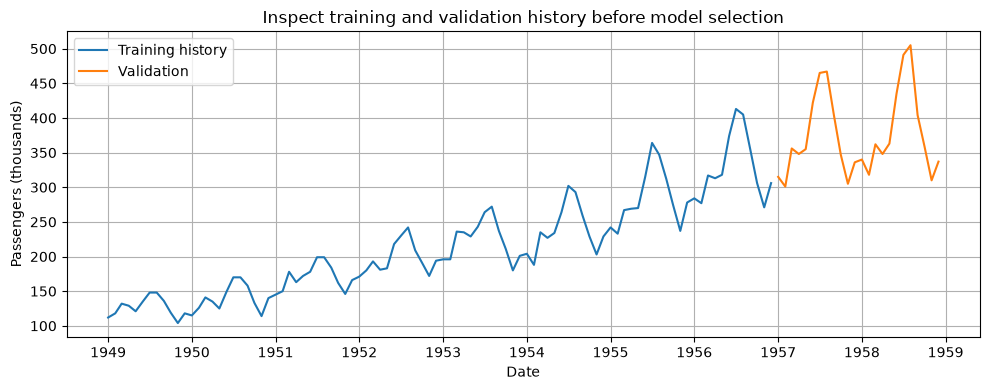

In [31]:
scaler = MinMaxScaler()
scaler.fit(values[:train_end])
scaled_values = scaler.transform(values).astype("float32")
np.testing.assert_allclose(scaler.data_min_, values[:train_end].min(axis=0))
np.testing.assert_allclose(scaler.data_max_, values[:train_end].max(axis=0))

split_summary = pd.DataFrame([
    {"Period": "Training history", "First date": dates[0].date(),
      "Last date": dates[train_end - 1].date(), "Rows": train_end},
    {"Period": "Validation targets", "First date": dates[train_end].date(),
      "Last date": dates[val_end - 1].date(), "Rows": val_end - train_end},
    {"Period": "Test targets", "First date": dates[val_end].date(),
      "Last date": dates[-1].date(), "Rows": len(values) - val_end},
])
print(split_summary.to_string(index=False))
print("Scaler minimum / maximum:", scaler.data_min_, scaler.data_max_)

plt.plot(dates[:train_end], values[:train_end, 0], label="Training history")
plt.plot(dates[train_end:val_end], values[train_end:val_end, 0], label="Validation")
plt.xlabel("Date")
plt.ylabel("Passengers (thousands)")
plt.title("Inspect training and validation history before model selection")
plt.legend()
plt.tight_layout()
plt.show()


## 3 · Turn a series into supervised examples

For target position `t`, the input is `values[t - LOOKBACK:t]` and the target is `values[t]`.
The right edge of a Python slice is excluded, so the target is never inside its own input.

Keras recurrent layers receive **(samples, timesteps, features)**. Here there is one measured
feature per step. The number of recurrent units is a separate model setting.
`Input(shape=(LOOKBACK, 1))` omits the batch dimension; it does not mean one timestep with
`LOOKBACK` features. With one timestep, a stateless model sees no earlier step within that sample.

We first create all eligible windows, then assign them by **target date**. Validation/test
windows may include earlier observed values from previous splits. This preserves the first
validation and test targets instead of throwing away a whole window at each boundary.

**Evaluation contract - rolling one-step prediction:** the model and scaler stay fixed. Before
predicting time `t`, all actual observations before `t` are available. Later test predictions
therefore use earlier observed test values. This is appropriate for a forecast updated every
period; it is not a forecast of the whole test period made at its first date.


In [32]:
def make_windows(scaled_values, lookback):
    if not 1 <= lookback < len(scaled_values):
        raise ValueError("LOOKBACK must leave at least one target.")
    target_pos = np.arange(lookback, len(scaled_values))
    X = np.stack([scaled_values[t - lookback:t] for t in target_pos])
    y = scaled_values[target_pos].copy()
    return X.astype("float32"), y.astype("float32"), target_pos

X_all, y_all, target_pos = make_windows(scaled_values, LOOKBACK)
train_mask = target_pos < train_end
val_mask = (target_pos >= train_end) & (target_pos < val_end)
test_mask = target_pos >= val_end

X_train, y_train = X_all[train_mask], y_all[train_mask]
X_val, y_val = X_all[val_mask], y_all[val_mask]
X_test, y_test = X_all[test_mask], y_all[test_mask]
train_pos, val_pos, test_pos = (target_pos[mask] for mask in
                                (train_mask, val_mask, test_mask))
assert len(X_train) > 0 and len(X_val) > 0 and len(X_test) > 0
assert X_train.shape[1:] == (LOOKBACK, 1)
assert y_train.shape == (len(X_train), 1)
assert val_pos[0] == train_end and test_pos[0] == val_end
assert test_pos[-1] == len(values) - 1
np.testing.assert_allclose(X_all[0], scaled_values[:LOOKBACK])
np.testing.assert_allclose(y_all[0], scaled_values[LOOKBACK])

print("X_train / y_train:", X_train.shape, y_train.shape)
print("X_val   / y_val:  ", X_val.shape, y_val.shape)
print("X_test  / y_test: ", X_test.shape, y_test.shape)
print("First validation window:", dates[val_pos[0] - LOOKBACK].date(),
      "to", dates[val_pos[0] - 1].date(),
      "→ target", dates[val_pos[0]].date())


X_train / y_train: (84, 12, 1) (84, 1)
X_val   / y_val:   (24, 12, 1) (24, 1)
X_test  / y_test:  (24, 12, 1) (24, 1)
First validation window: 1956-01-01 to 1956-12-01 → target 1957-01-01


## 4 · Compare two baselines

**Persistence:** `prediction[t] = value[t - 1]`.

**Seasonal naive:** `prediction[t] = value[t - 12]`, the observed count for the same month
one year earlier. The 12-month lag is motivated by the monthly calendar; it is independent
of the neural network's `LOOKBACK`. Both baselines use only information available before `t`.

Compare all methods on the same validation target months. MAE is the average absolute error;
RMSE gives more weight to larger errors. Their unit here is **thousands of passengers**.
A small neural network is not guaranteed to beat either baseline.


In [33]:
def error_scores(actual, predicted):
    actual = np.asarray(actual).ravel()
    predicted = np.asarray(predicted).ravel()
    if actual.shape != predicted.shape:
        raise ValueError("Actual and predicted values must have identical targets.")
    return {"MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(mean_squared_error(actual, predicted))}


In [34]:
SEASON = 12
assert val_pos.min() >= SEASON and test_pos.min() >= SEASON
val_actual = values[val_pos, 0].copy()
val_last = values[val_pos - 1, 0].copy()
val_seasonal = values[val_pos - SEASON, 0].copy()
baseline_validation = pd.DataFrame({
    "Last observed value": error_scores(val_actual, val_last),
    "Same month last year": error_scores(val_actual, val_seasonal),
}).T
baseline_validation.round(3)


,MAE,RMSE
Last observed value,35.875,43.983
Same month last year,26.375,31.698


## 5 · Train a small LSTM

One 16-unit recurrent layer is enough to inspect this learning pipeline. More layers or
dropout are experiments, not guaranteed improvements. This is a compact teaching model.

With `return_sequences=False` (the default), the recurrent layer returns one vector of
shape `(batch, UNITS)`, and Dense maps it to `(batch, 1)`. Setting `return_sequences=True`
returns `(batch, LOOKBACK, UNITS)` and is needed when feeding a second recurrent layer.
The default setup has **1,169 trainable parameters**.

We pass an explicit chronological validation set. Early stopping monitors validation loss
and restores the best weights. `shuffle=False` makes the walkthrough easier to follow;
the primary protection against leakage is the chronological split and correct windows.
These models are stateless: hidden state is not carried from one sample to the next.

Documentation: [recurrent layer](https://keras.io/api/layers/recurrent_layers/lstm/),
[EarlyStopping](https://keras.io/api/callbacks/early_stopping/),
[random seeds](https://keras.io/api/utils/python_utils/#set_random_seed-function).


In [35]:
import keras

keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
if keras.backend.backend() == "torch":
    import torch
    torch.set_num_threads(1)  # Small CPU models rarely benefit from many threads.

print("Keras:", keras.__version__, "| Backend:", keras.backend.backend())
# Seeding supports repeatable comparisons, but exact results may differ across
# library versions, hardware and backend kernels.


Keras: 3.15.1 | Backend: torch


In [36]:
model = keras.Sequential([
    keras.Input(shape=(LOOKBACK, 1)),
    keras.layers.LSTM(UNITS),
    keras.layers.Dense(1),
])
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="mse"
)
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 16)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,169 (4.57 KB)

 Trainable params: 1,169 (4.57 KB)

 Non-trainable params: 0 (0.00 B)

Ran 30 epochs; lowest validation loss at epoch 30.


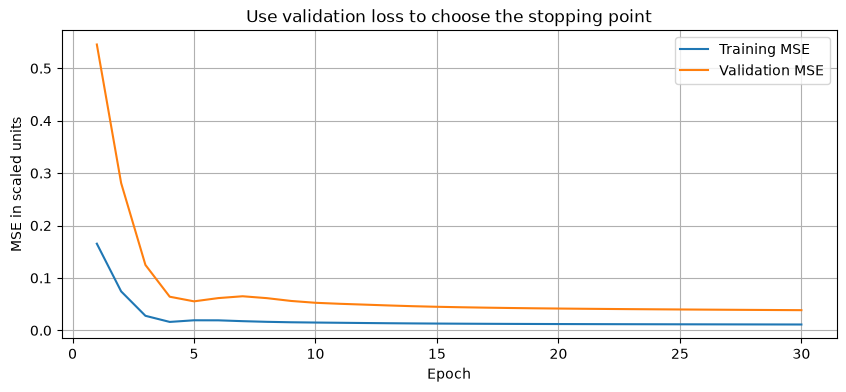

In [37]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, min_delta=0.0,
    restore_best_weights=True
)
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=MAX_EPOCHS, batch_size=BATCH_SIZE,
    shuffle=False, callbacks=[early_stop], verbose=0
)
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print(f"Ran {len(history.history['loss'])} epochs; lowest validation loss at epoch {best_epoch}.")

epochs = np.arange(1, len(history.history["loss"]) + 1)
plt.plot(epochs, history.history["loss"], label="Training MSE")
plt.plot(epochs, history.history["val_loss"], label="Validation MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE in scaled units")
plt.title("Use validation loss to choose the stopping point")
plt.legend()
plt.show()


## 6 · Compare on validation dates in original units

Inverse-transform predictions into a new array. Do not overwrite `y_train`, `y_val` or
`y_test`; they stay as scaled column vectors so that re-running training remains valid.
Record your configuration and validation metrics before changing one setting.


                         MAE    RMSE
Last observed value   35.875  43.983
Same month last year  26.375  31.698
LSTM                  48.213  60.703
{'LOOKBACK': 12, 'UNITS': 16, 'seed': 42, 'epochs_run': 30, 'best_epoch': 30}


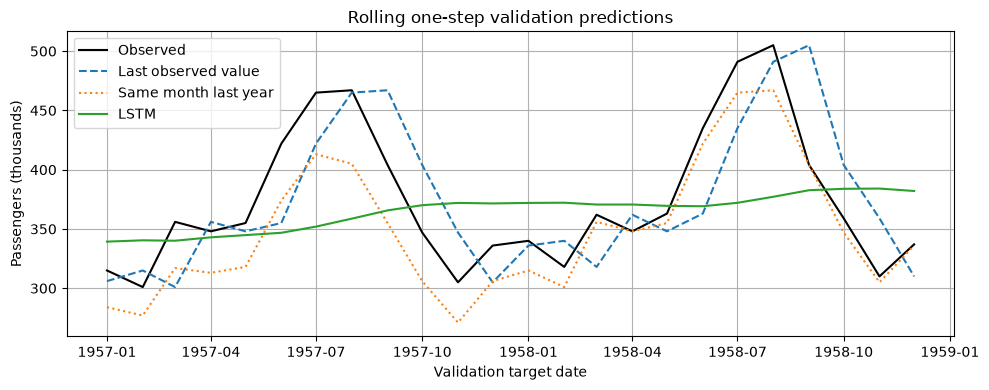

In [38]:
val_pred_scaled = model.predict(X_val, verbose=0)
val_pred = scaler.inverse_transform(val_pred_scaled)[:, 0]
validation_scores = pd.concat([
    baseline_validation,
    pd.DataFrame([error_scores(val_actual, val_pred)], index=["LSTM"])
])
print(validation_scores.round(3).to_string())
print({"LOOKBACK": LOOKBACK, "UNITS": UNITS, "seed": SEED,
       "epochs_run": len(history.history["loss"]), "best_epoch": best_epoch})

plt.plot(dates[val_pos], val_actual, label="Observed", color="black")
plt.plot(dates[val_pos], val_last, label="Last observed value", linestyle="--")
plt.plot(dates[val_pos], val_seasonal, label="Same month last year", linestyle=":")
plt.plot(dates[val_pos], val_pred, label="LSTM")
plt.xlabel("Validation target date")
plt.ylabel("Passengers (thousands)")
plt.title("Rolling one-step validation predictions")
plt.legend()
plt.tight_layout()
plt.show()


## Learner response · complete before the final test

**Shape and data explanation:** The excluded row is the text footer at the bottom of the CSV. It isn’t a real month, so the loading code drops it, leaving 144 months (1949 to 1960). X_train is (84, 12, 1): 84 windows, 12 months in each, 1 feature (passenger count). The first validation example uses Jan to Dec 1956 to predict Jan 1957. Fitting the scaler on all 144 months would leak the size of future values, so I fit it on the 96 training months only. Later scaled values go above 1 because passenger numbers keep growing past the training maximum.

**Hypothesis written before running alternatives:** I expect the 12-month window to do best on validation. The data repeats every 12 months, so a 12-month window covers one full yearly cycle. A 6-month window can't see the same month from last year, and a 24-month window should contain more history than needed while leaving fewer training samples (72 instead of 84) for a model that already has very little data. I don't expect any LSTM to beat the same-month-last-year baseline.

| Lookback | Units | Train samples | Epochs run | Validation MAE | Validation RMSE |
|---|---|---|---|---|---|
| 6 | 16 |  90 | 30 | 58.808 | 74.917 |
| 12 | 16 | 84 | 30 | 48.213 | 60.703 |
| 24 | 16 |  72 | 10 | 49.142 | 66.893 |

**Baseline validation scores:** last observed value has MAE 35.875 and RMSE 43.983. Same month last year has MAE 26.375 and RMSE 31.698. The seasonal baseline is better, and no LSTM run beat either one.

**Chosen configuration and evidence:** I chose LOOKBACK = 12, because it had the lowest validation MAE (48.213, versus 49.142 for 24 and 58.808 for 6). The gap to 24 is small and it’s only one seed, so the result isn’t strong. The 24-month run also stopped early at epoch 10, while the others ran all 30. My hypothesis that 12 would be best was supported, but it still loses to both baselines.

**What remained constant?** The split, seed (42), units (16), optimizer, learning rate, batch size, max epochs and early stopping rule were all the same. Only LOOKBACK changed. Training samples went from 90 to 84 to 72 as the window got longer, because longer windows need more history before the first target. The validation and test months stayed the same.

## 7 · Freeze the configuration, then evaluate test once

Before this section, record the chosen settings and why validation supports them.
Use the selected model already trained above; this lab does not refit on validation data.
Do not use the final test score to choose another configuration.

The model predicts every held-out target using the actual history available immediately
before it. There is no model/scaler refitting during these months. All methods use exactly
the same target dates. The starter skips this section until you set `RUN_FINAL_TEST = True` after completing the core tasks.


                         MAE    RMSE
Last observed value   44.208  51.782
Same month last year  47.583  49.987
LSTM                  58.997  82.379
Final configuration: {'LOOKBACK': 12, 'UNITS': 16, 'seed': 42, 'best_epoch': 30}
Test targets scored: 24


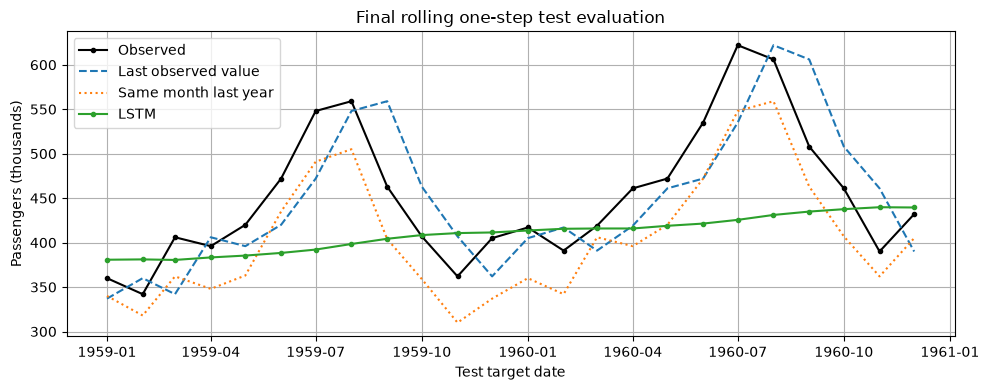

In [40]:
RUN_FINAL_TEST = True

if RUN_FINAL_TEST:
    test_actual = values[test_pos, 0].copy()
    test_last = values[test_pos - 1, 0].copy()
    test_pred = scaler.inverse_transform(model.predict(X_test, verbose=0))[:, 0]
    test_scores = pd.DataFrame({
        "Last observed value": error_scores(test_actual, test_last),
        "Same month last year": error_scores(test_actual, values[test_pos - SEASON, 0]),
        "LSTM": error_scores(test_actual, test_pred),
    }).T
    print(test_scores.round(3).to_string())
    print("Final configuration:", {"LOOKBACK": LOOKBACK, "UNITS": UNITS,
                                   "seed": SEED, "best_epoch": best_epoch})
    print("Test targets scored:", len(test_actual))

    plt.plot(dates[test_pos], test_actual, label="Observed", color="black", marker=".")
    plt.plot(dates[test_pos], test_last, label="Last observed value", linestyle="--")
    plt.plot(dates[test_pos], values[test_pos - SEASON, 0],
             label="Same month last year", linestyle=":")
    plt.plot(dates[test_pos], test_pred, label="LSTM", marker=".")
    plt.xlabel("Test target date")
    plt.ylabel("Passengers (thousands)")
    plt.title("Final rolling one-step test evaluation")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Test remains held out. Complete validation experiments and freeze settings first.")


In [42]:
print("Training max:", values[:train_end].max())
print("Test max:", values[test_pos, 0].max())

Training max: 413.0
Test max: 622.0


## Final learner report and discussion

**Final test scores and limitation:** On the 24 test months, last observed value scored MAE 44.208 and RMSE 51.782. Same month last year scored MAE 47.583 and RMSE 49.987. The LSTM (12 months, 16 units) scored MAE 58.997 and RMSE 82.379, so it didn’t beat either baseline. One limitation is that the test period is only 24 months, and the 1959 and 1960 passenger numbers are much higher than anything in training. It’s also a single seed, and the model hit the 30-epoch limit.

Discuss: If the next real observation isn’t available, the model would have to use its own predictions as input, and the errors would add up, so these one-step scores would look better than they really are. Using earlier test values is fine here because in real use last month’s actual number is already known when you predict this month. Fitting on test targets isn’t fine, because then the model learns the answers it’s supposed to predict and the score means nothing.

## Optional extensions · after the core work

- Compare SimpleRNN and LSTM on **this same airline task** with the same split and target dates.
  The separate stock lab cannot establish which architecture is better.
- Try modelling log passenger counts. Fit the scaler on transformed training values only,
  then invert both transforms before scoring.
- Explore more recurrent units only after fixing the window; more capacity may overfit this small series.
- Design a genuine multi-step experiment from a fixed forecast origin. If later observations
  are unknown, feed back predictions recursively or train a direct multi-output model. Evaluate
  each horizon using matching-origin baselines. The one-step score above does not measure this task.

## Sources and attribution

- Original supplied notebook attributed its tutorial to
  [moonglow22, RNN and LSTM tutorial for beginners](https://www.kaggle.com/code/moonglow22/rnn-and-lstm-tutorial-for-beginners/notebook)
  and stated Apache 2.0 for that notebook. This attribution is retained; it is not a data license.
- Data: [Kaggle dataset, version 1](https://www.kaggle.com/datasets/andreazzini/international-airline-passengers).
  The source metadata reports **Unknown** license. Included CSVs are source copies for review;
  see `data/DATA_SOURCES.md` in the complete pack before wider distribution.
- [Keras backend setup](https://keras.io/getting_started/),
  [MinMaxScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html),
  [avoiding preprocessing leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage),
  [KaggleHub versioned downloads](https://github.com/Kaggle/kagglehub#download-dataset).
